In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter('ignore')

In [2]:
df = pd.read_csv(r"agentic_reality.csv")   # update the path if needed
df.head()

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
0,AGP-0001,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51
1,AGP-0002,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78
2,AGP-0003,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91
3,AGP-0004,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75
4,AGP-0005,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58


In [3]:
df.shape

(2500, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Project_ID               2500 non-null   object 
 1   Industry                 2500 non-null   object 
 2   Agent_Type               2500 non-null   object 
 3   Primary_Tool             2500 non-null   object 
 4   Status                   2500 non-null   object 
 5   Failure_Reason           2154 non-null   object 
 6   Human_in_the_Loop_Ratio  2500 non-null   float64
 7   Tokens_per_Task          2500 non-null   int64  
 8   ROI_Score                2500 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 175.9+ KB


In [5]:
df.isnull().sum()

Project_ID                   0
Industry                     0
Agent_Type                   0
Primary_Tool                 0
Status                       0
Failure_Reason             346
Human_in_the_Loop_Ratio      0
Tokens_per_Task              0
ROI_Score                    0
dtype: int64

In [6]:
# Drop irrelevant columns (Failure_Reason has missing values and is not needed for clustering)
df.drop(['Project_ID', 'Failure_Reason'], axis=1, inplace=True)

In [7]:
df.shape

(2500, 7)

In [8]:
features = ['Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score']
df[features].isnull().sum()

Human_in_the_Loop_Ratio    0
Tokens_per_Task            0
ROI_Score                  0
dtype: int64

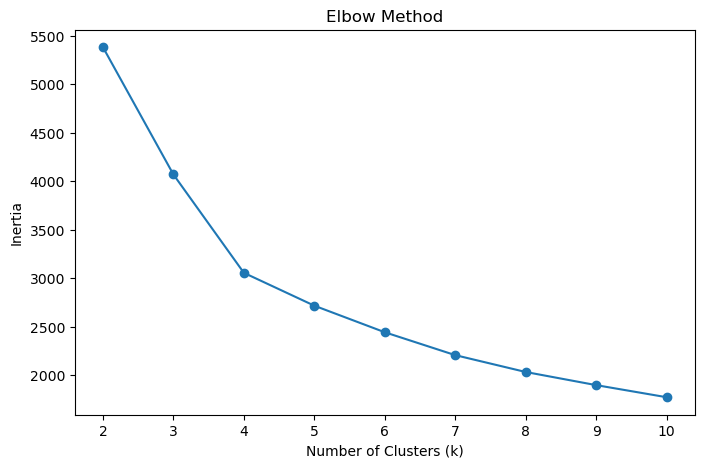

In [22]:
# Elbow Method
from sklearn.cluster import KMeans

inertia = []
K = range(2, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(K)
plt.show()

In [9]:
X = df[features].values

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [12]:
from sklearn.cluster import DBSCAN

dbs = DBSCAN(eps=0.5, min_samples=5)

y_dbs = dbs.fit_predict(X_scaled)

In [13]:
df['cluster'] = y_dbs

In [14]:
df['cluster'].unique()

array([ 0, -1,  1,  3,  2])

In [15]:
# -1 means noise / outliers
df['cluster'].value_counts().sort_index()

cluster
-1      80
 0    2399
 1       8
 2       8
 3       5
Name: count, dtype: int64

In [16]:
print('Clusters found:', len(set(y_dbs)) - (1 if -1 in y_dbs else 0))
print('Noise points  :', (y_dbs == -1).sum())

Clusters found: 4
Noise points  : 80


In [17]:
df[df['cluster'] == 0]

,Industry,Agent_Type,Primary_Tool,Status,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,cluster
0,Insurance,Autonomous,LangGraph,Production,0.389,2094,2.51,0
1,Retail,Assistant,CrewAI,Production,0.990,5993,3.78,0
2,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,0.475,9032,0.91,0
3,Technology,Multi-agent Swarm,LangGraph,Pilot,0.372,8735,0.75,0
4,Finance,Autonomous,LangGraph,Production,0.613,1645,2.58,0
...,...,...,...,...,...,...,...,...
2495,Manufacturing,Autonomous,CrewAI,Pilot,0.266,5788,-0.14,0
2496,Manufacturing,Autonomous,LangGraph,Pilot,0.162,3609,1.73,0
2497,Healthcare,Assistant,CrewAI,Pilot,0.799,3182,0.63,0
2498,Energy,Assistant,CrewAI,Pilot,0.571,5360,-0.28,0


In [18]:
# average values of each cluster
df.groupby('cluster')[features].mean()

,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
cluster,,,
-1,0.48205,10028.975000,1.537500
0,0.48478,4927.026261,0.384577
1,0.66025,11760.750000,0.977500
2,0.33475,10286.250000,1.863750
3,0.56420,14381.400000,-0.802000


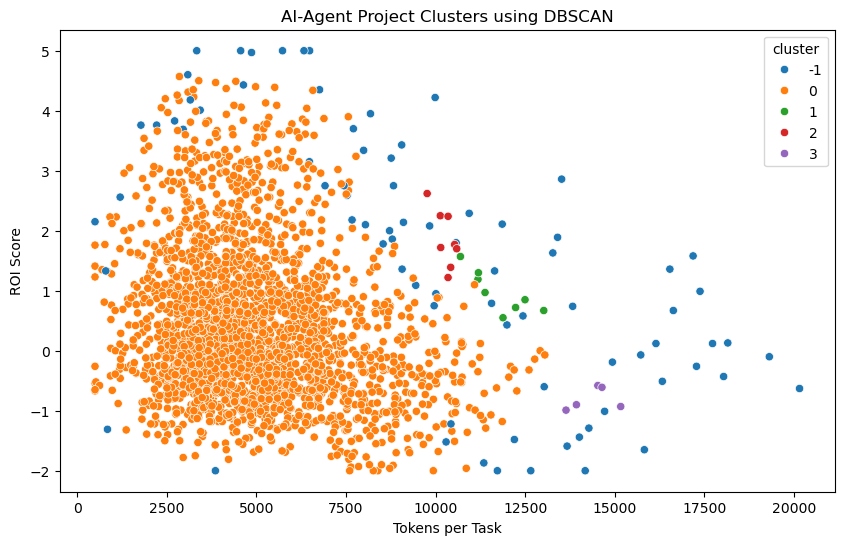

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Tokens_per_Task',
    y='ROI_Score',
    hue='cluster',
    palette='tab10'
)

plt.title('AI-Agent Project Clusters using DBSCAN')
plt.xlabel('Tokens per Task')
plt.ylabel('ROI Score')
plt.show()

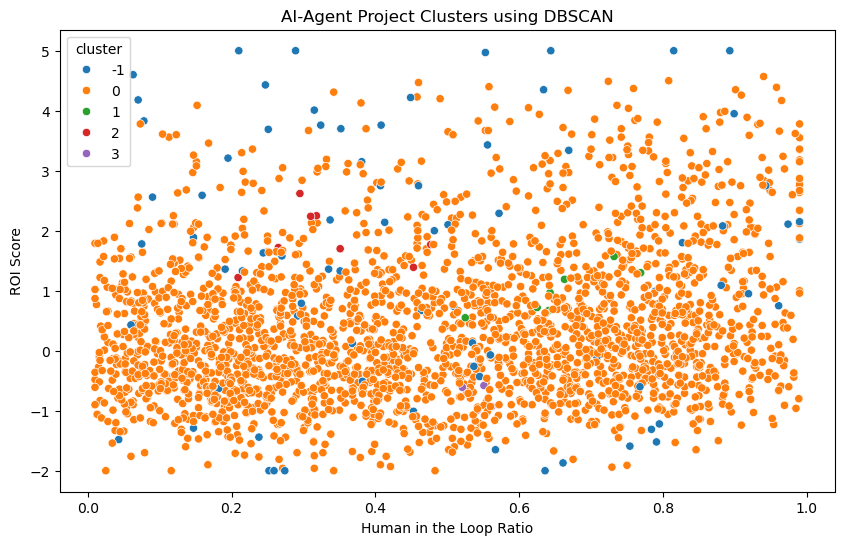

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Human_in_the_Loop_Ratio',
    y='ROI_Score',
    hue='cluster',
    palette='tab10'
)

plt.title('AI-Agent Project Clusters using DBSCAN')
plt.xlabel('Human in the Loop Ratio')
plt.ylabel('ROI Score')
plt.show()

In [21]:
# Industry distribution across clusters
pd.crosstab(df['cluster'], df['Industry'])

Industry,Energy,Finance,Government,Healthcare,Insurance,Legal,Manufacturing,Retail,Technology,Telecom
cluster,,,,,,,,,,
-1,5,8,4,14,10,7,4,14,10,4
0,150,397,193,314,178,176,213,299,332,147
1,0,3,0,0,2,0,0,2,1,0
2,0,1,1,1,0,0,0,2,2,1
3,0,1,1,0,0,1,0,1,0,1
